In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report,confusion_matrix

import tensorflow as tf

import cv2
import os

import numpy as np


In [3]:

# labels =["Agaricus", "Amanita","Boletus","Cortinarius","Entoloma","Exidia","Hygrocybe","Inocybe","Lactarius","Pluteus","Russula","Suillus"]
# img_size = 32
# def get_data(data_dir):
#     data = []
#     for label in labels:
#         path = os.path.join(data_dir, label)
#         class_num = labels.index(label)
#         for img in os.listdir(path):
#             try:
#                 img_arr = cv2.imread(os.path.join(path, img))[...,::-1] #convert BGR to RGB format
#                 resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size
#                 data.append([resized_arr, class_num])
#             except Exception as e:
#                 print(e)
#     return np.array(data)

In [4]:
# import os
# import cv2
# import numpy as np

# labels = ["Agaricus", "Amanita", "Boletus", "Cortinarius", "Entoloma", "Exidia", "Hygrocybe", "Inocybe", "Lactarius", "Pluteus", "Russula", "Suillus"]
# img_size = 32

# def get_data(data_dir):
#     images = []
#     classes = []

#     for label in labels:
#         path = os.path.join(data_dir, label)
#         class_num = labels.index(label)

#         for img in os.listdir(path):
#             try:
#                 img_arr = cv2.imread(os.path.join(path, img))[...,::-1] #convert BGR to RGB format
#                 resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size

#                 images.append(resized_arr)
#                 classes.append(class_num)
#             except Exception as e:
#                 print(e)

#     return np.array(images), np.array(classes)

# # Example usage:
# # images, classes = get_data('/content/drive/MyDrive/Mushroom/Dataset')


In [5]:
# images, classes = get_data('/content/drive/MyDrive/Mushroom/Dataset')

In [6]:

# train = get_data('/content/drive/MyDrive/Mushroom/Dataset')

In [7]:
import os
import cv2
import numpy as np

labels = [
    "Aair", "Black Roi", "Boal", "Chapila", "Common Carp", "DeshiPuti", "Foli",
    "Grass Carp", "Ilish", "KalBaush", "Katla", "Koi", 
    "Magur", "Mirror Carp", "Mrigel", "Nile Telapiya", "Pabda", "Pangas", "Puti",
    "Rui","Shing","Shol", "Shorputi", "Silver Carp", "Taki", "Tarabaim", "Telapiya", "Tengra"
]
img_size = 32

def get_data(data_dir):
    images = []  # Array to store resized image arrays
    classes = []  # Array to store corresponding class numbers
    for label in labels:
        path = os.path.join(data_dir, label)
        class_num = labels.index(label)
        for img in os.listdir(path):
            try:
                img_arr = cv2.imread(os.path.join(path, img))[...,::-1] # Convert BGR to RGB format
                resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshape images to preferred size
                images.append(resized_arr)
                classes.append(class_num)
            except Exception as e:
                print(e)
    return np.array(images), np.array(classes)

# Example usage:
data_dir = '/kaggle/input/split-dataset-of-fish/split dataset of fish/train'
images, classes = get_data(data_dir)
print(images.shape)  # Print the shape of the loaded images
print(classes.shape)  # Print the shape of the loaded classes


(58800, 32, 32, 3)
(58800,)


In [ ]:
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt

# # Assuming train is a tuple containing (images, classes) from the previous function

# # Creating a list of labels based on class numbers
# label_map = {
#     0: "Agaricus", 1: "Amanita", 2: "Boletus", 3: "Cortinarius",
#     4: "Entoloma", 5: "Exidia", 6: "Hygrocybe", 7: "Inocybe",
#     8: "Lactarius", 9: "Pluteus", 10: "Russula", 11: "Amanita"
# }

# labels = [label_map[class_num] for class_num in classes]

# if len(labels) > 0:
#     sns.set_style('darkgrid')
#     sns.countplot(x="label", hue="class", data=pd.DataFrame({"label": labels, "class": classes}))
#     plt.show()
# else:
#     print("No data found for the given labels.")


In [8]:
# Library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.image import imread
import cv2
import random
from os import listdir
from sklearn.preprocessing import  LabelBinarizer
from keras.preprocessing import image
from keras.preprocessing.image import img_to_array, array_to_img
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Activation, Flatten, Dropout, Dense
from sklearn.model_selection import train_test_split

NameError: name 'label_map' is not defined

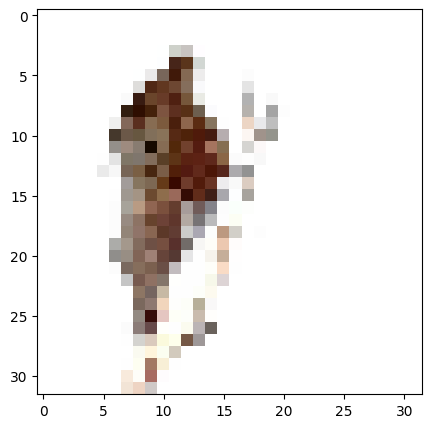

In [9]:
import matplotlib.pyplot as plt

# Assuming train is a tuple containing (images, classes) from the previous function

plt.figure(figsize=(5, 5))
plt.imshow(images[1])  # Assuming you want to display the second image
plt.title(label_map[classes[1]])  # Assuming you want to display the label corresponding to the second image
plt.show()


In [ ]:
# x_train = []
# y_train = []


# for feature, label in train:
#   x_train.append(feature)
#   y_train.append(label)
# x_train = np.array(x_train) / 255
# x_train.reshape(-1, img_size, img_size, 1)
# y_train = np.array(y_train)

In [10]:
import numpy as np

# Assuming train is a tuple containing (images, classes) obtained using the get_data function

x_train = []
y_train = []

for feature, label in zip(images, classes):
    x_train.append(feature)
    y_train.append(label)

x_train = np.array(x_train) / 255.0  # Normalize pixel values to range [0, 1]
x_train = x_train.reshape(-1, img_size, img_size, 3)  # Reshape x_train to match the expected input shape
y_train = np.array(y_train)


In [11]:
print(x_train.shape)

(58800, 32, 32, 3)


In [12]:
# split with a stratified sampling
from sklearn.model_selection import train_test_split
(x_train, x_test, y_train, y_test) = train_test_split(x_train, y_train,
    test_size=0.20, stratify=y_train, random_state=42)

In [13]:

!pip install -U -q tensorflow-addons

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.8/611.8 kB 13.9 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.16.1 requires typeguard<5,>=3, but you have typeguard 2.13.3 which is incompatible.
inflect 7.5.0 requires typeguard>=4.0.1, but you have typeguard 2.13.3 which is incompatible.


In [15]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
# import tensorflow_addons as tfa

In [16]:
num_classes = 28
input_shape = (32, 32, 3)

In [17]:
print(f"x_train shape: {x_train.shape} - y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape} - y_test shape: {y_test.shape}")

x_train shape: (47040, 32, 32, 3) - y_train shape: (47040,)
x_test shape: (11760, 32, 32, 3) - y_test shape: (11760,)


In [18]:
learning_rate = 0.001
weight_decay = 0.0001
batch_size = 128
num_epochs = 100
image_size = 32  # We'll resize input images to this size
patch_size = 6  # Size of the patches to be extract from the input images
num_patches = (image_size // patch_size) ** 2
projection_dim = 64
num_heads = 2
transformer_units = [
    projection_dim * 2,
    projection_dim,
]  # Size of the transformer layers
transformer_layers = 1
mlp_head_units = [2048, 1024]

In [19]:
data_augmentation = keras.Sequential(
    [
        layers.Normalization(),
        layers.Resizing(image_size, image_size),
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(factor=0.02),
        layers.RandomZoom(
            height_factor=0.2, width_factor=0.2
        ),
    ],
    name="data_augmentation",
)
# Compute the mean and the variance of the training data for normalization.
data_augmentation.layers[0].adapt(x_train)


I0000 00:00:1750568619.893014      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [20]:
def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

In [21]:
class Patches(layers.Layer):
    def __init__(self, patch_size):
        super(Patches, self).__init__()
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches

Image size: 32 X 32
Patch size: 6 X 6
Patches per image: 25
Elements per patch: 108


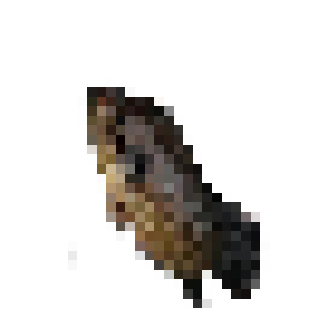

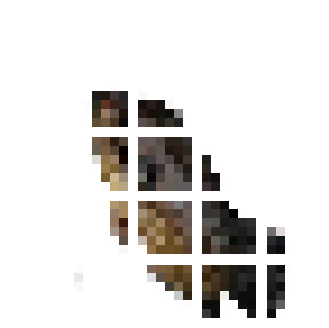

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
image = x_train[np.random.choice(range(x_train.shape[0]))]
plt.imshow(image.astype("float"))
plt.axis("off")

resized_image = tf.image.resize(
    tf.convert_to_tensor([image]), size=(image_size, image_size)
)
patches = Patches(patch_size)(resized_image)
print(f"Image size: {image_size} X {image_size}")
print(f"Patch size: {patch_size} X {patch_size}")
print(f"Patches per image: {patches.shape[1]}")
print(f"Elements per patch: {patches.shape[-1]}")

n = int(np.sqrt(patches.shape[1]))
plt.figure(figsize=(4, 4))
for i, patch in enumerate(patches[0]):
    ax = plt.subplot(n, n, i + 1)
    patch_img = tf.reshape(patch, (patch_size, patch_size, 3))
    plt.imshow(patch_img.numpy().astype("float"))
    plt.axis("off")

In [23]:
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super(PatchEncoder, self).__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded

In [24]:
def create_vit_classifier():
    inputs = layers.Input(shape=input_shape)
    # Augment data.
    augmented = data_augmentation(inputs)
    # Create patches.
    patches = Patches(patch_size)(augmented)
    # Encode patches.
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    # Create multiple layers of the Transformer block.
    for _ in range(transformer_layers):
        # Layer normalization 1.
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        # Skip connection 1.
        x2 = layers.Add()([attention_output, encoded_patches])
        # Layer normalization 2.
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # MLP.
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)
        # Skip connection 2.
        encoded_patches = layers.Add()([x3, x2])

    # Create a [batch_size, projection_dim] tensor.
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    # Add MLP.
    features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)
    # Classify outputs.
    logits = layers.Dense(num_classes)(features)
    # Create the Keras model.
    model = keras.Model(inputs=inputs, outputs=logits)
    return model

In [25]:
# Merge inputs and targets
inputs = np.concatenate((x_train, x_test), axis=0)
targets = np.concatenate((y_train, y_test), axis=0)

In [26]:
# Define per-fold score containers
acc_per_fold = []
loss_per_fold = []

In [27]:
from sklearn.model_selection import KFold

------------------------------------------------------------------------
Training for fold 1 ...
Epoch 1/100
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1238 - loss: 3.1730 - top-5-accuracy: 0.4228
Epoch 1: val_accuracy improved from -inf to 0.34924, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.1242 - loss: 3.1702 - top-5-accuracy: 0.4236 - val_accuracy: 0.3492 - val_loss: 2.0788 - val_top-5-accuracy: 0.7637
Epoch 2/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3034 - loss: 2.2317 - top-5-accuracy: 0.7286
Epoch 2: val_accuracy improved from 0.34924 to 0.43001, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3037 - loss: 2.2308 - top-5-accuracy: 0.7289 - val_accuracy: 0.4300 - val_loss: 1.7789 - val_top-5-accuracy: 0.8290
Epoch 3/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3669 - loss: 2.0029 - top-5-accuracy: 0.7879
Epoch 3: val_accuracy improved from 0.43001 

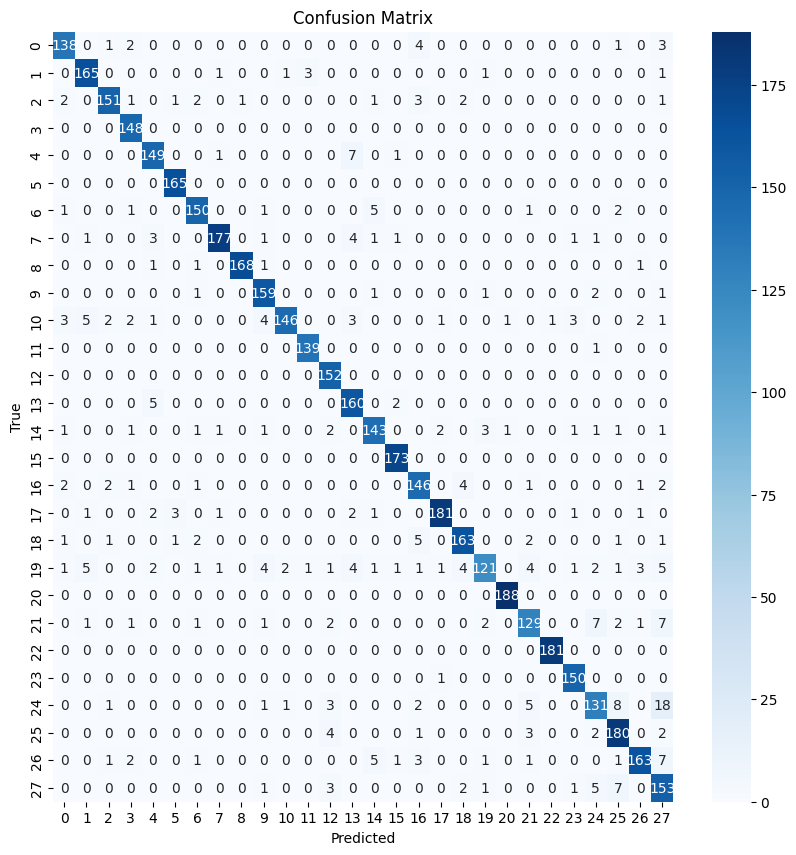

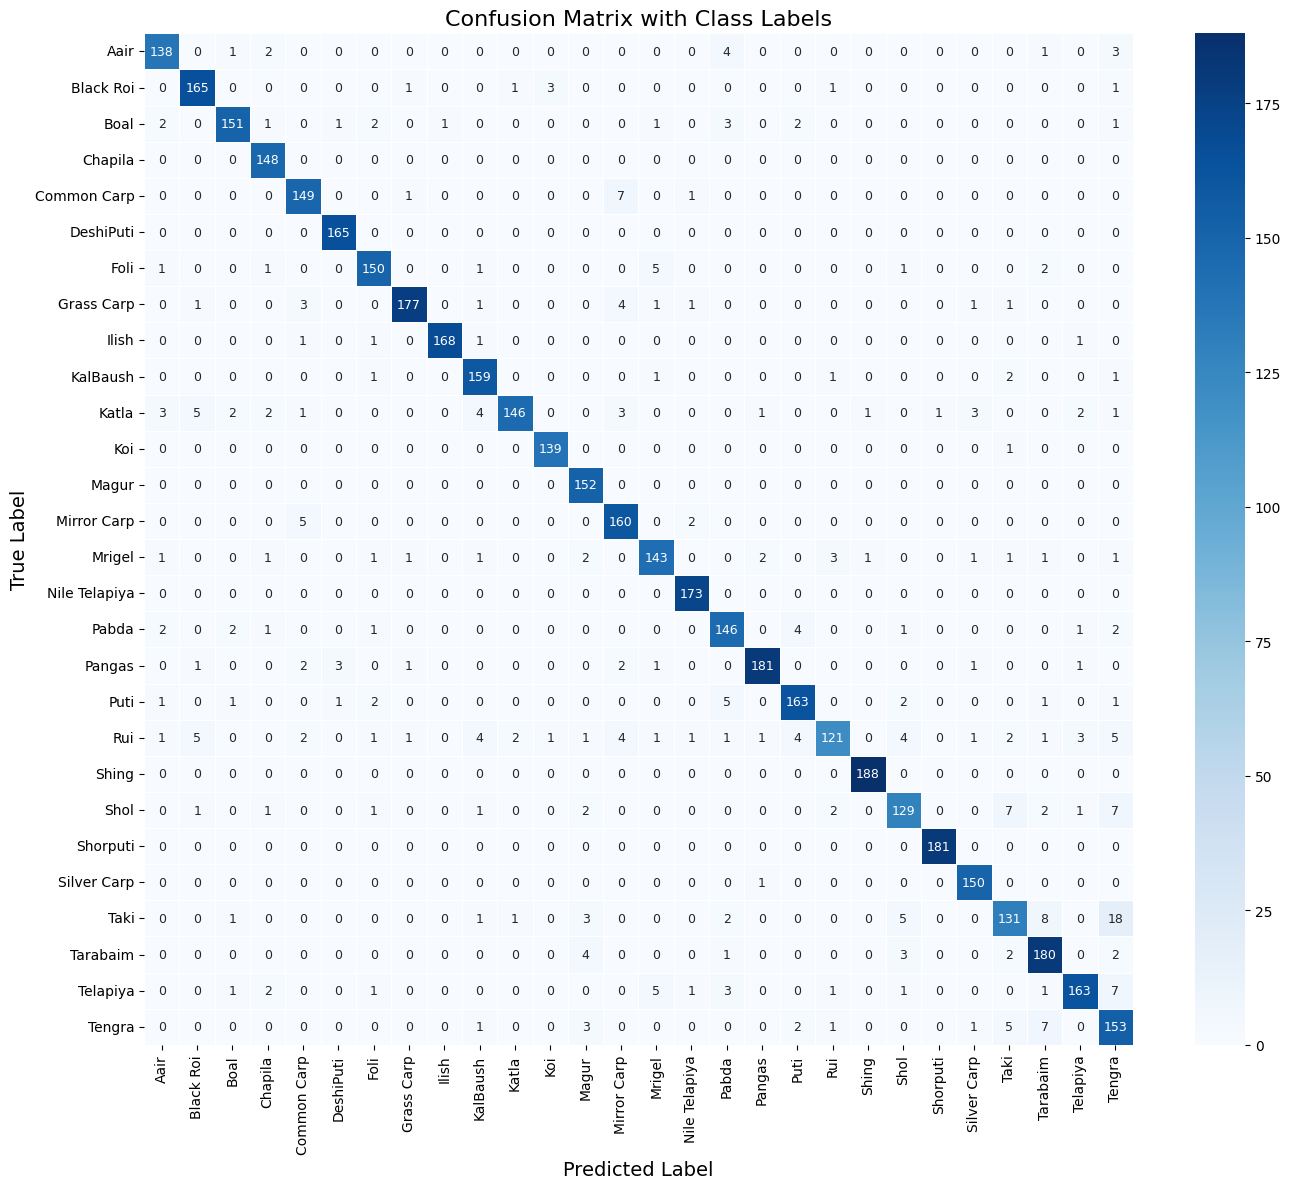

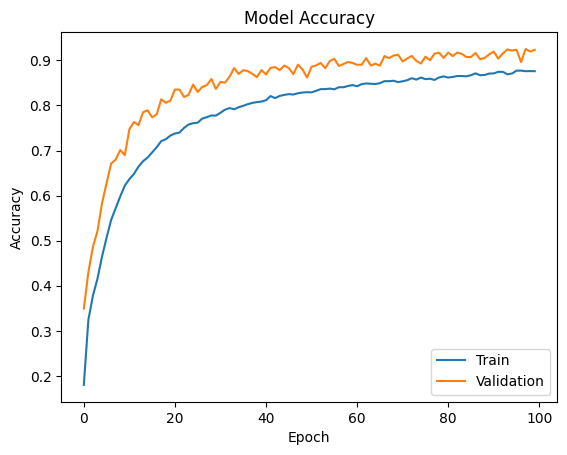

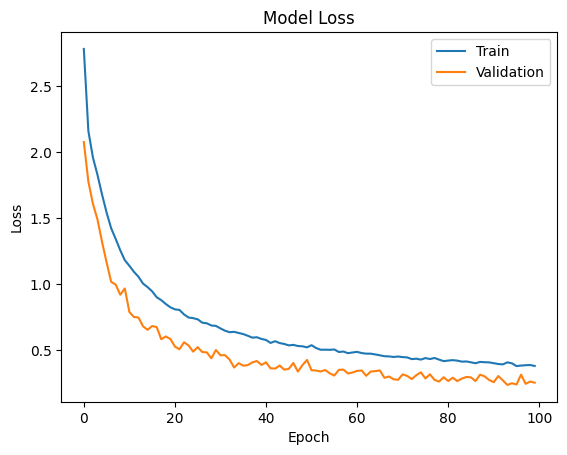

------------------------------------------------------------------------
Training for fold 2 ...
Epoch 1/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1315 - loss: 3.1401 - top-5-accuracy: 0.4356
Epoch 1: val_accuracy improved from -inf to 0.36388, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1321 - loss: 3.1360 - top-5-accuracy: 0.4368 - val_accuracy: 0.3639 - val_loss: 2.0310 - val_top-5-accuracy: 0.7725
Epoch 2/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3113 - loss: 2.2017 - top-5-accuracy: 0.7404
Epoch 2: val_accuracy improved from 0.36388 to 0.44371, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3116 - loss: 2.2003 - top-5-accuracy: 0.7407 - val_accuracy: 0.4437 - val_loss: 1.7249 - val_top-5-accuracy: 0.8466
Epoch 3/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3844 - loss: 1.9317 - top-5-accuracy: 0.8059
Epoch 3: val_accuracy improved from 0.44371 

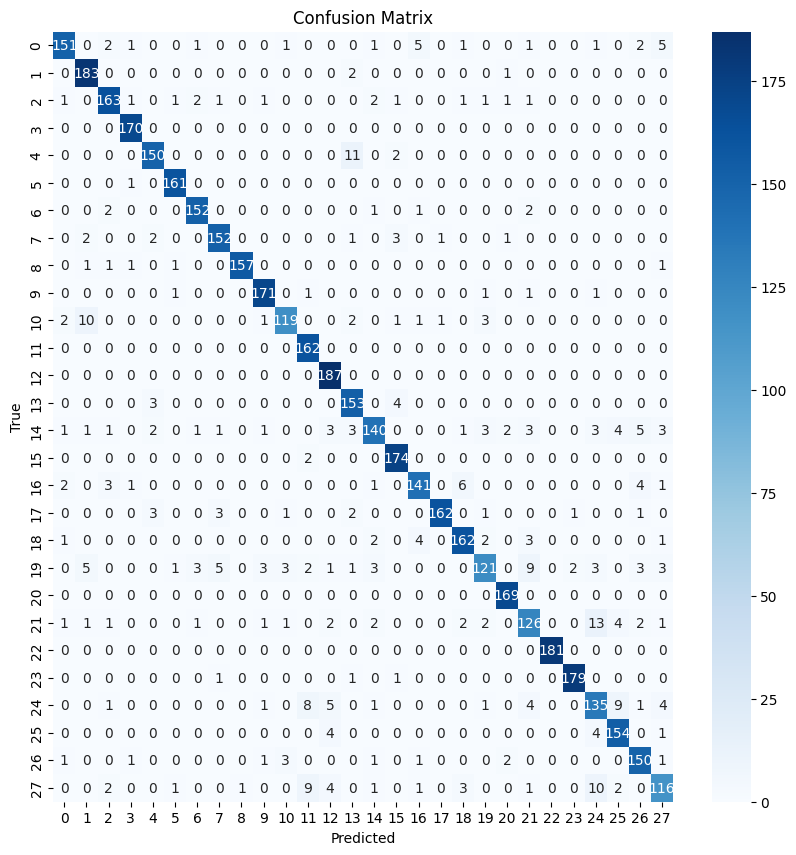

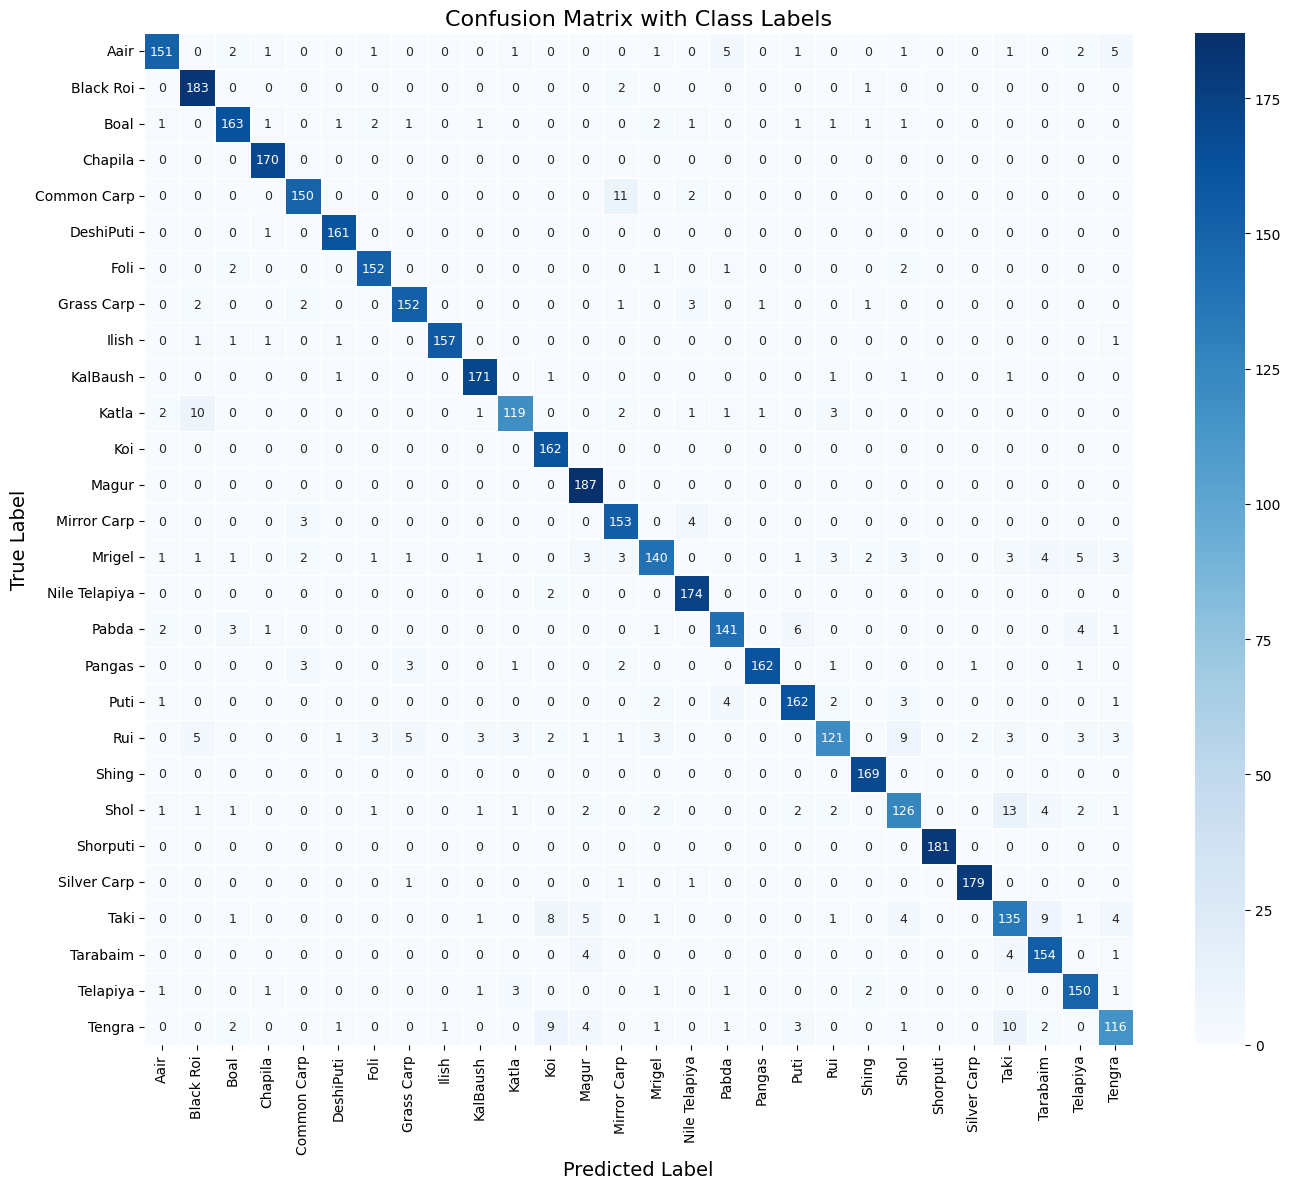

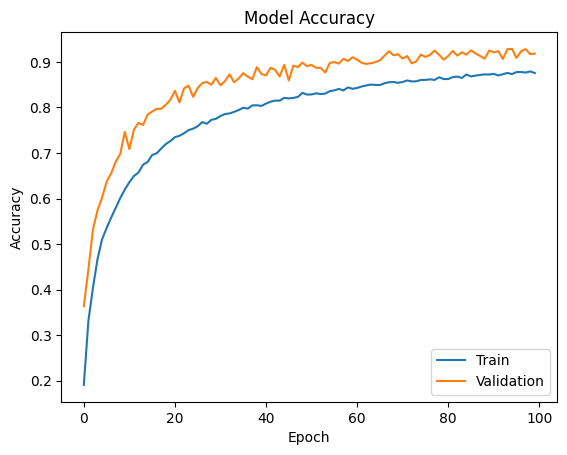

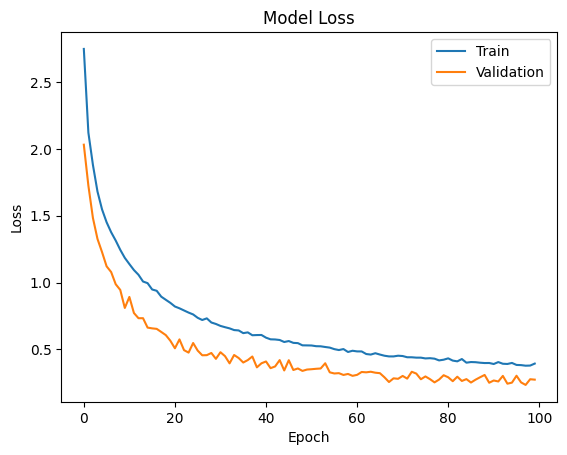

------------------------------------------------------------------------
Training for fold 3 ...
Epoch 1/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1341 - loss: 3.1350 - top-5-accuracy: 0.4324
Epoch 1: val_accuracy improved from -inf to 0.35065, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1351 - loss: 3.1278 - top-5-accuracy: 0.4347 - val_accuracy: 0.3507 - val_loss: 2.0682 - val_top-5-accuracy: 0.7618
Epoch 2/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3115 - loss: 2.1940 - top-5-accuracy: 0.7416
Epoch 2: val_accuracy improved from 0.35065 to 0.45394, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3118 - loss: 2.1930 - top-5-accuracy: 0.7419 - val_accuracy: 0.4539 - val_loss: 1.7122 - val_top-5-accuracy: 0.8468
Epoch 3/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3792 - loss: 1.9528 - top-5-accuracy: 0.7982
Epoch 3: val_accuracy improved from 0.45394 

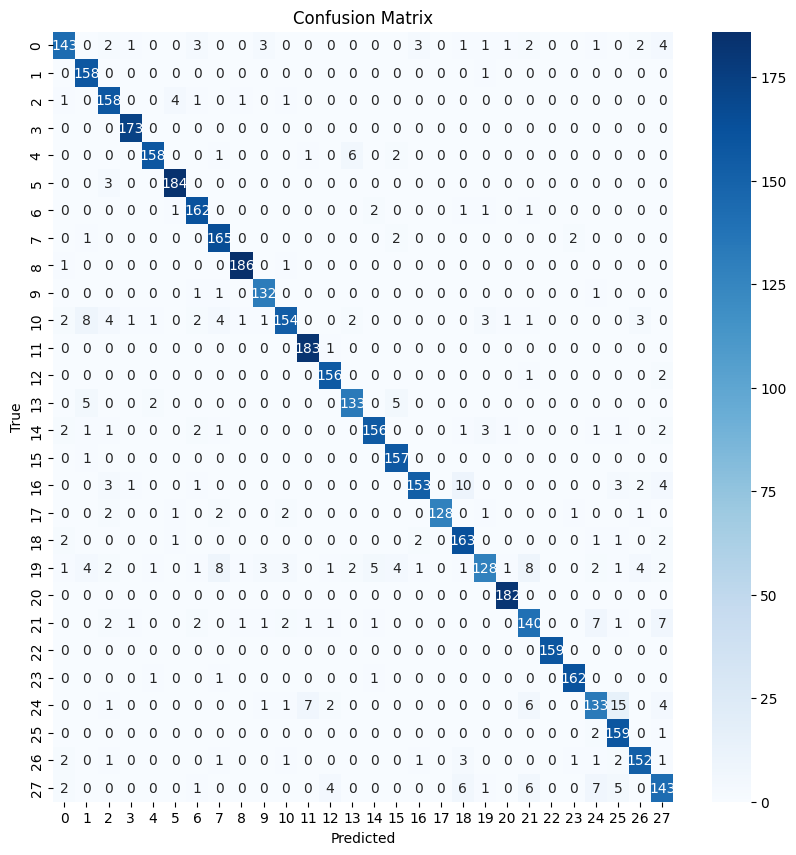

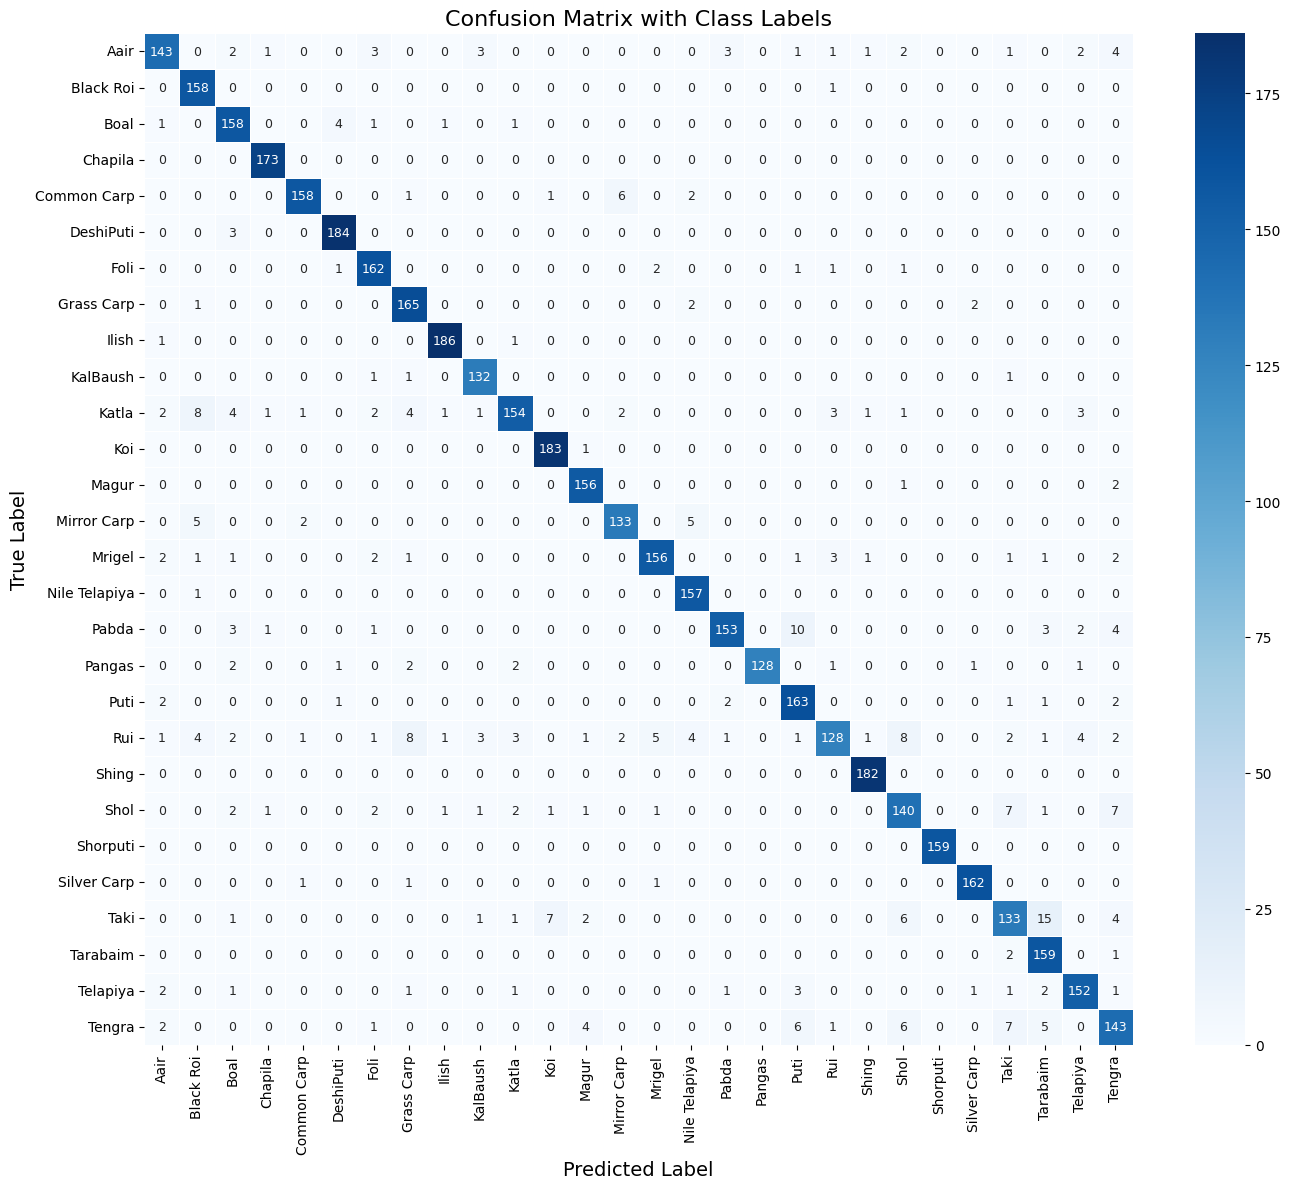

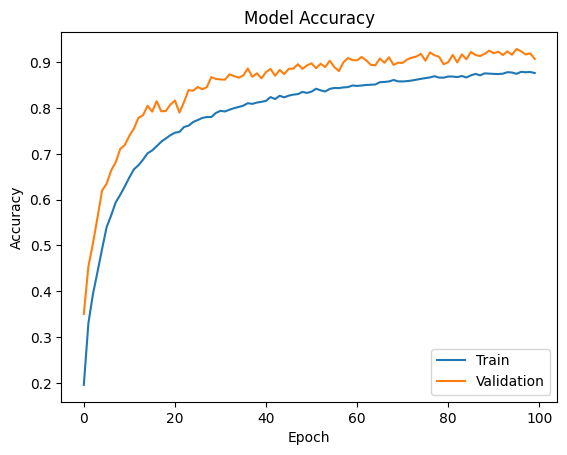

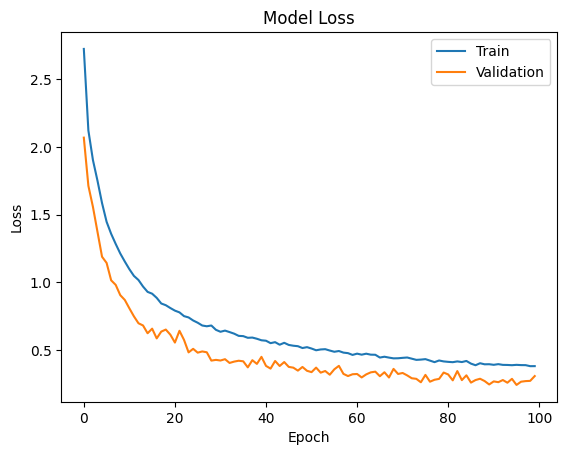

------------------------------------------------------------------------
Training for fold 4 ...
Epoch 1/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1357 - loss: 3.1429 - top-5-accuracy: 0.4350
Epoch 1: val_accuracy improved from -inf to 0.37837, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1364 - loss: 3.1385 - top-5-accuracy: 0.4363 - val_accuracy: 0.3784 - val_loss: 2.0130 - val_top-5-accuracy: 0.7791
Epoch 2/100
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3153 - loss: 2.2001 - top-5-accuracy: 0.7366
Epoch 2: val_accuracy improved from 0.37837 to 0.45725, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3154 - loss: 2.1995 - top-5-accuracy: 0.7367 - val_accuracy: 0.4573 - val_loss: 1.7171 - val_top-5-accuracy: 0.8378
Epoch 3/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3781 - loss: 1.9536 - top-5-accuracy: 0.7987
Epoch 3: val_accuracy improved from 0.45725 

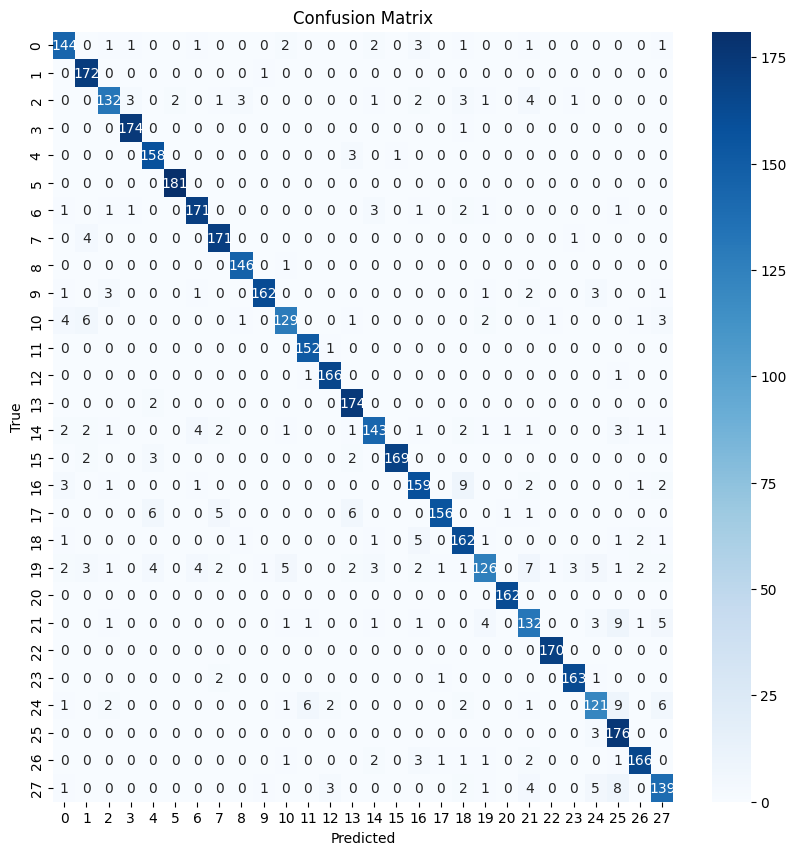

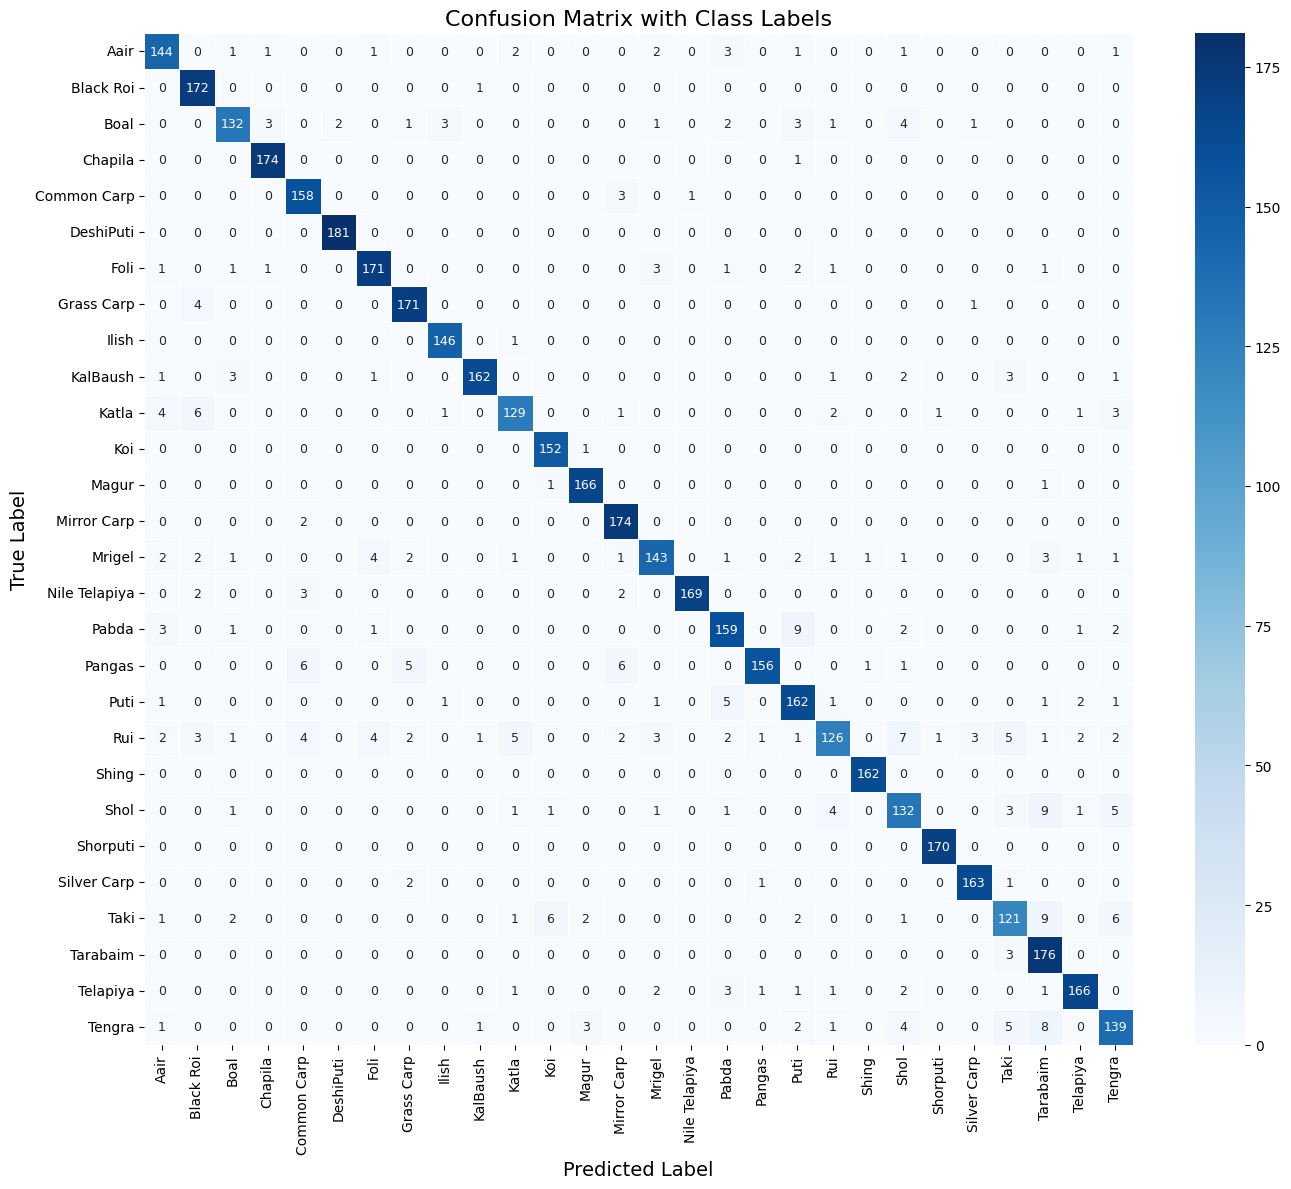

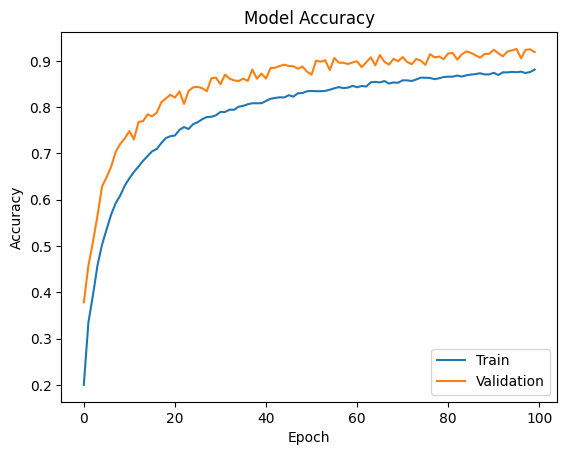

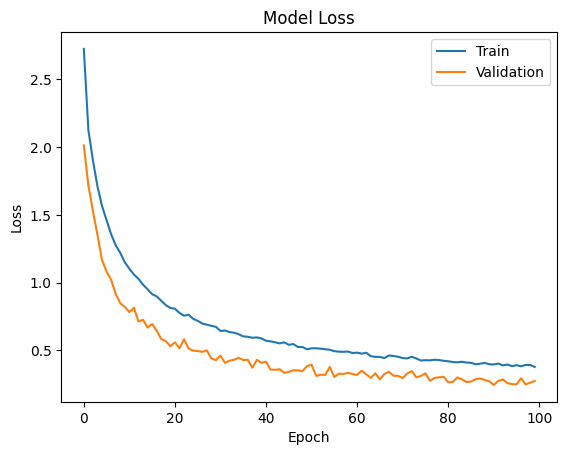

------------------------------------------------------------------------
Training for fold 5 ...
Epoch 1/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1356 - loss: 3.1290 - top-5-accuracy: 0.4424
Epoch 1: val_accuracy improved from -inf to 0.37207, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.1365 - loss: 3.1230 - top-5-accuracy: 0.4442 - val_accuracy: 0.3721 - val_loss: 1.9904 - val_top-5-accuracy: 0.7796
Epoch 2/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3138 - loss: 2.1947 - top-5-accuracy: 0.7423
Epoch 2: val_accuracy improved from 0.37207 to 0.44418, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3140 - loss: 2.1939 - top-5-accuracy: 0.7425 - val_accuracy: 0.4442 - val_loss: 1.7197 - val_top-5-accuracy: 0.8444
Epoch 3/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3842 - loss: 1.9518 - top-5-accuracy: 0.7987
Epoch 3: val_accuracy improved from 0.44418 

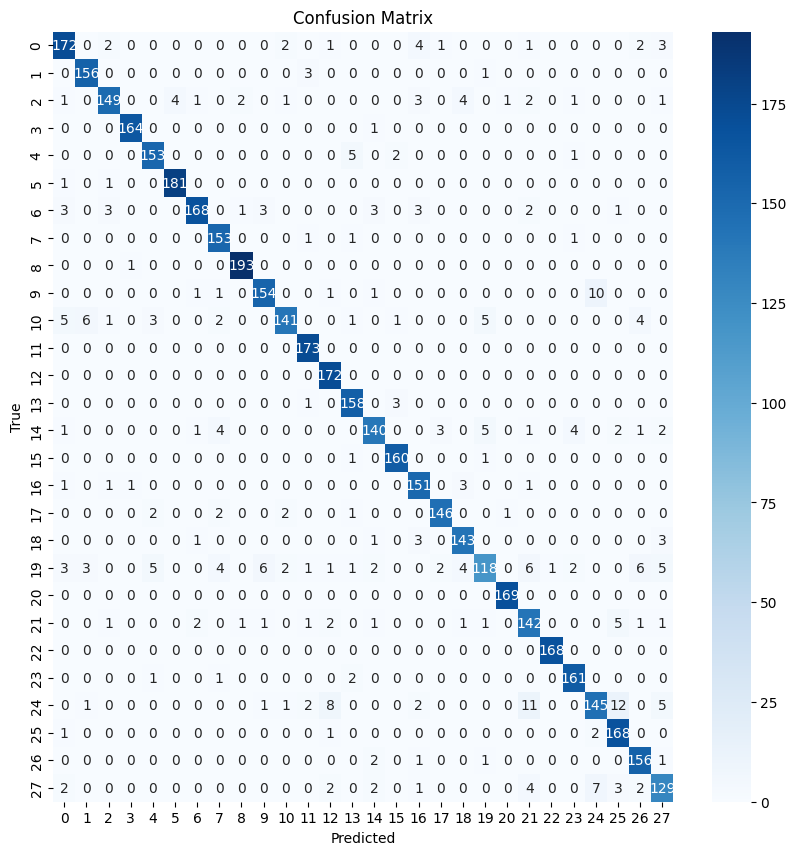

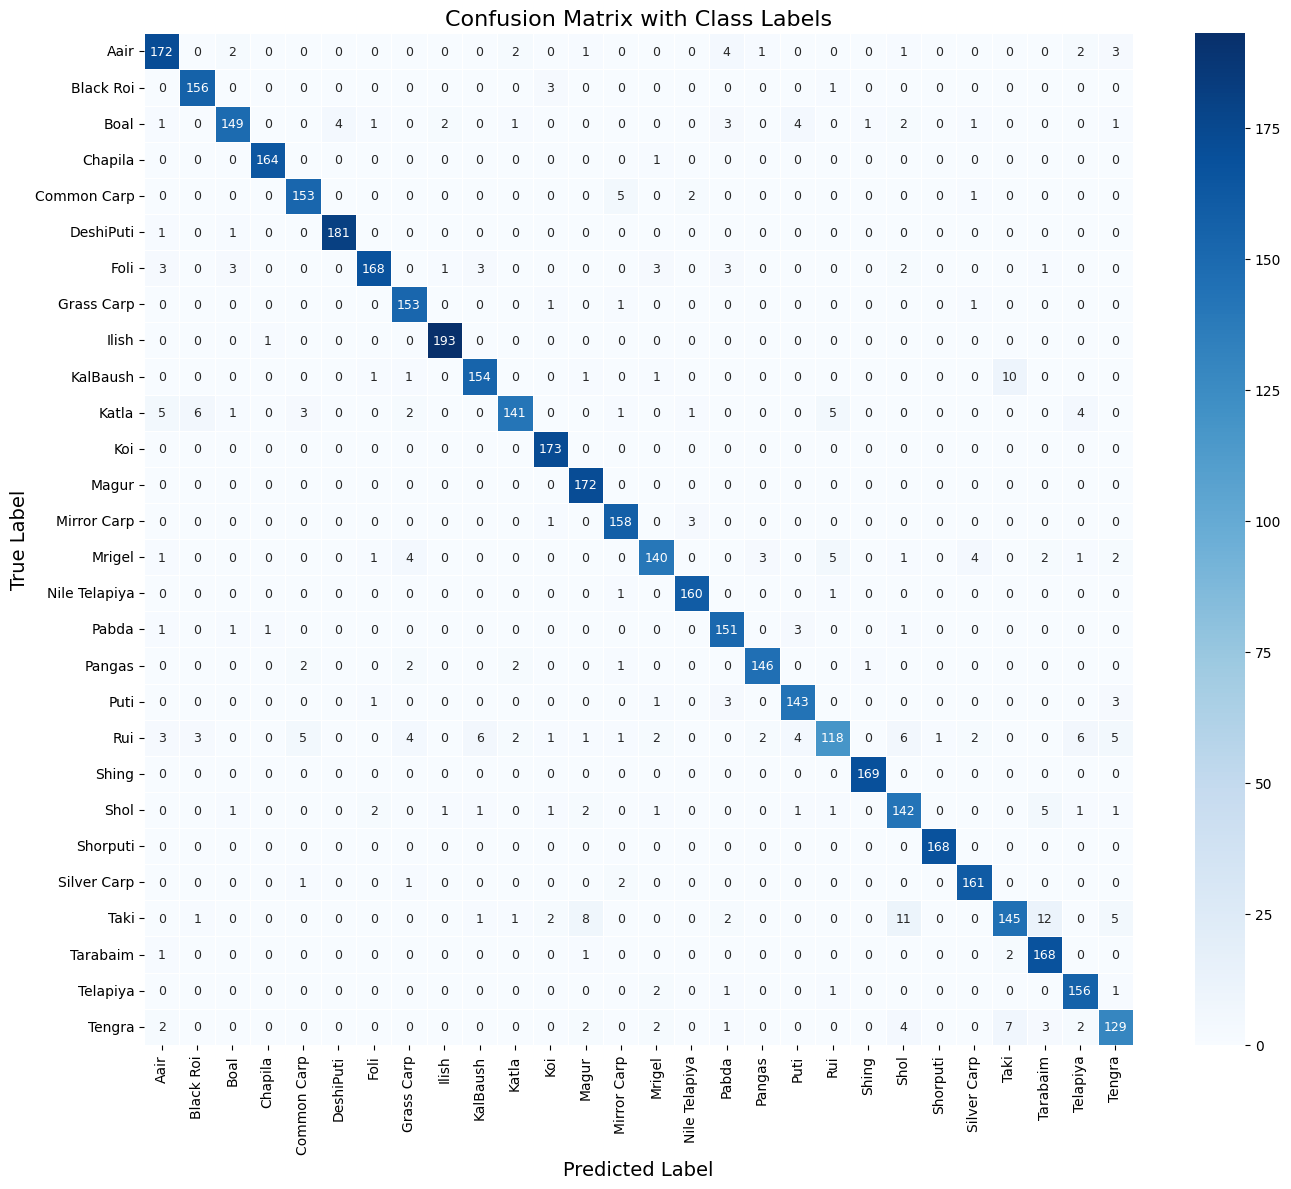

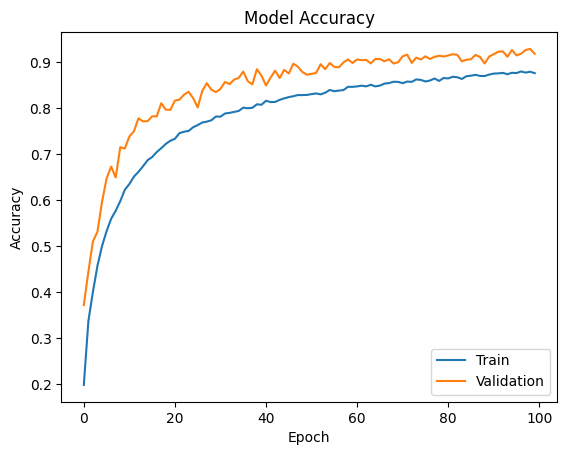

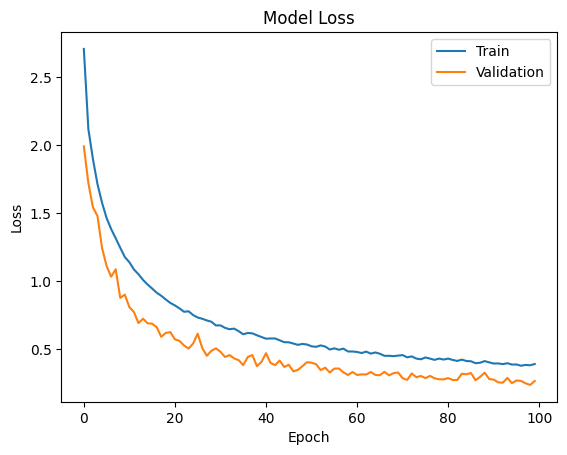

------------------------------------------------------------------------
Training for fold 6 ...
Epoch 1/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1316 - loss: 3.1409 - top-5-accuracy: 0.4353
Epoch 1: val_accuracy improved from -inf to 0.36498, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.1322 - loss: 3.1365 - top-5-accuracy: 0.4366 - val_accuracy: 0.3650 - val_loss: 2.0196 - val_top-5-accuracy: 0.7824
Epoch 2/100
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3102 - loss: 2.1914 - top-5-accuracy: 0.7381
Epoch 2: val_accuracy improved from 0.36498 to 0.44481, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.3103 - loss: 2.1909 - top-5-accuracy: 0.7383 - val_accuracy: 0.4448 - val_loss: 1.7456 - val_top-5-accuracy: 0.8344
Epoch 3/100
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3871 - loss: 1.9271 - top-5-accuracy: 0.8057
Epoch 3: val_accuracy improved from 0.44481 

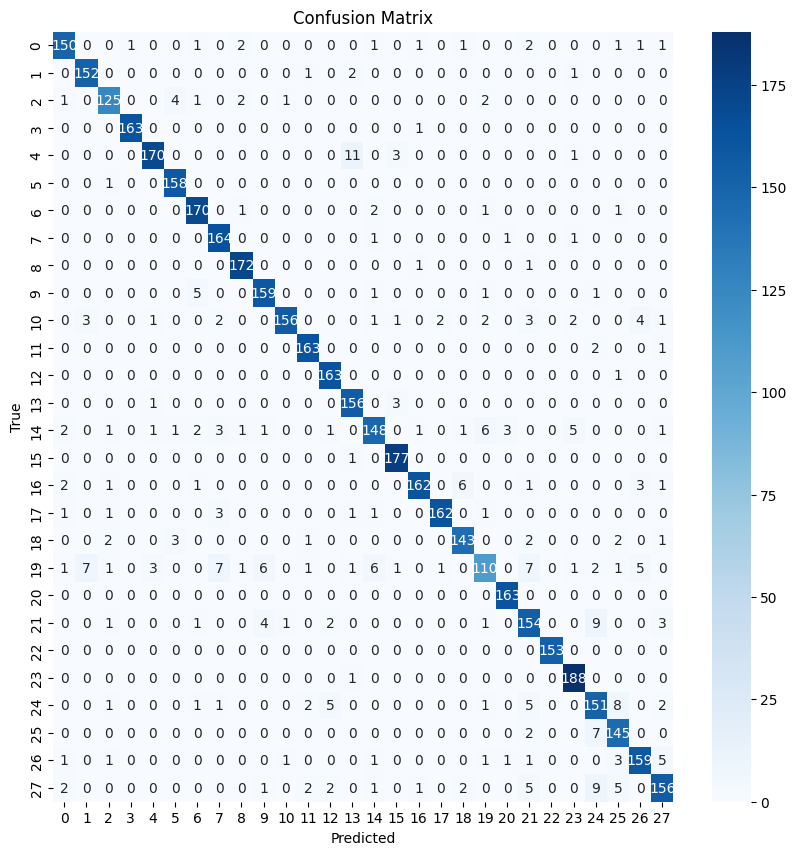

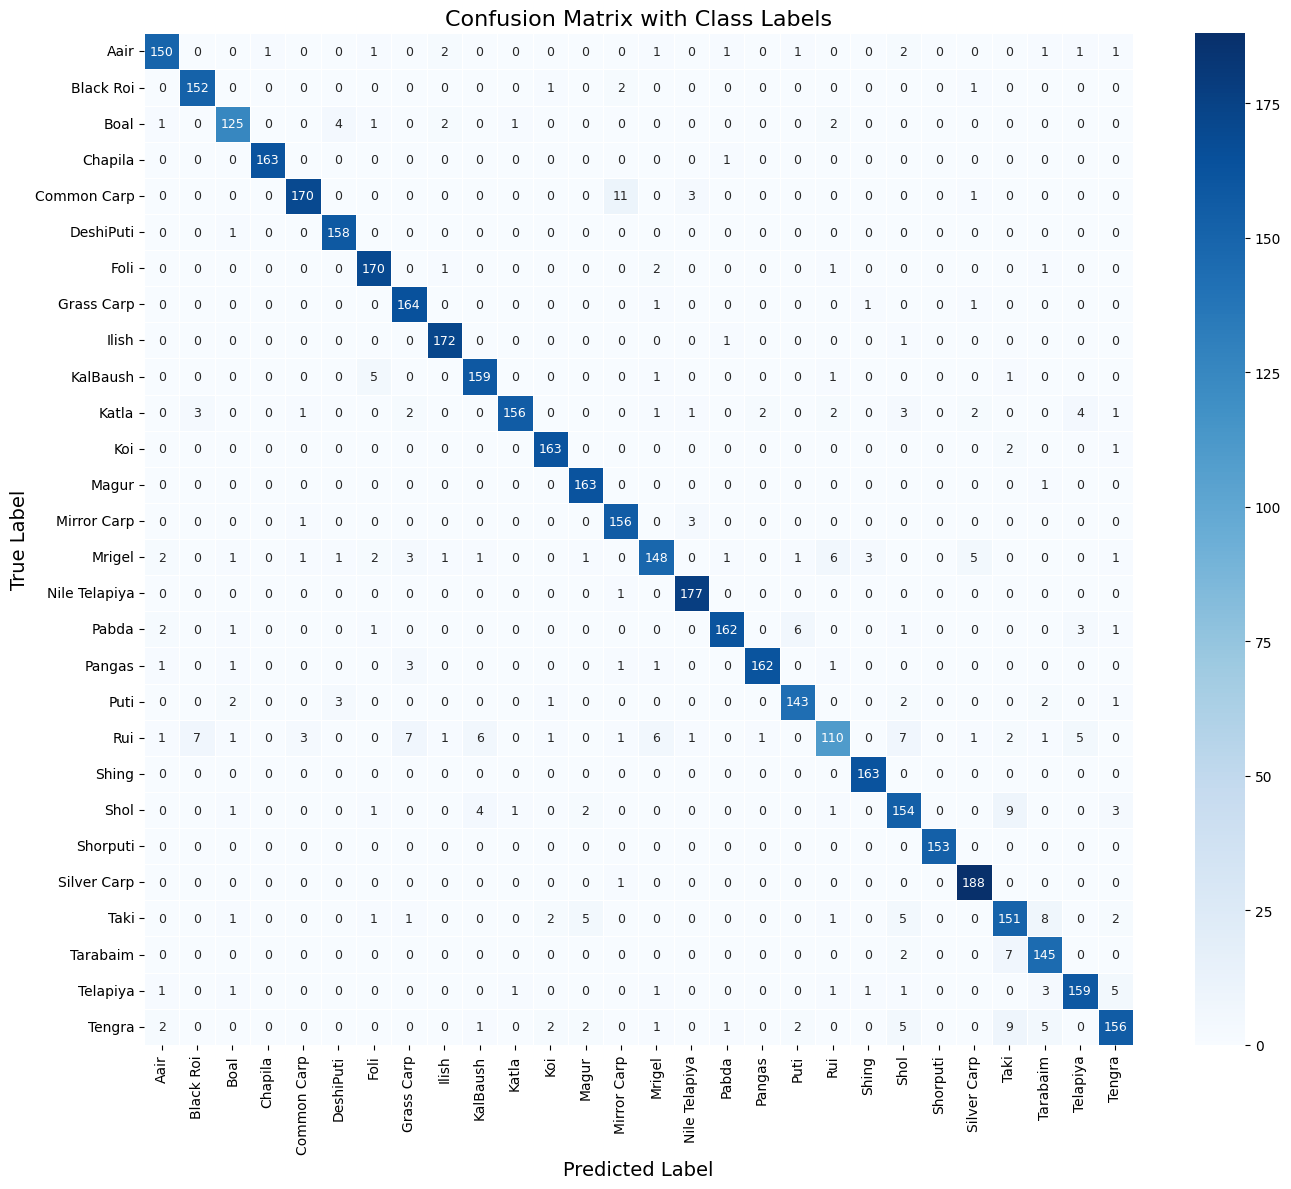

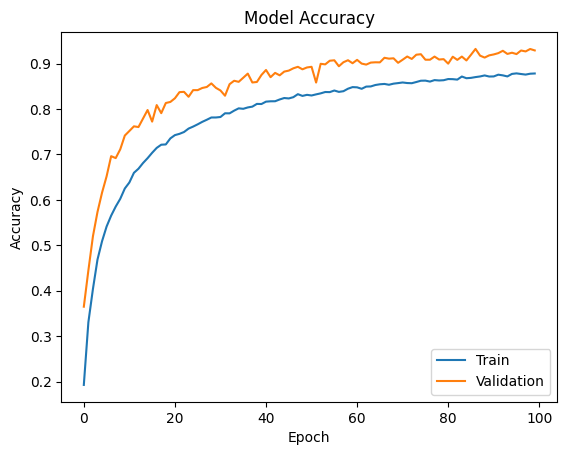

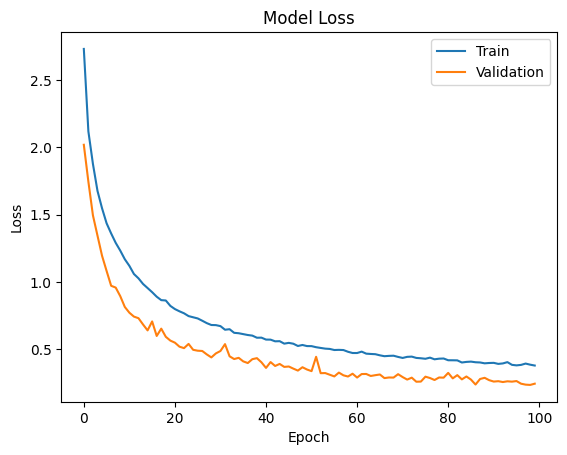

------------------------------------------------------------------------
Training for fold 7 ...
Epoch 1/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1234 - loss: 3.1709 - top-5-accuracy: 0.4265
Epoch 1: val_accuracy improved from -inf to 0.35207, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.1244 - loss: 3.1637 - top-5-accuracy: 0.4285 - val_accuracy: 0.3521 - val_loss: 2.0641 - val_top-5-accuracy: 0.7597
Epoch 2/100
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3031 - loss: 2.2228 - top-5-accuracy: 0.7353
Epoch 2: val_accuracy improved from 0.35207 to 0.43159, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3031 - loss: 2.2226 - top-5-accuracy: 0.7354 - val_accuracy: 0.4316 - val_loss: 1.7702 - val_top-5-accuracy: 0.8348
Epoch 3/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3811 - loss: 1.9570 - top-5-accuracy: 0.8025
Epoch 3: val_accuracy improved from 0.43159 

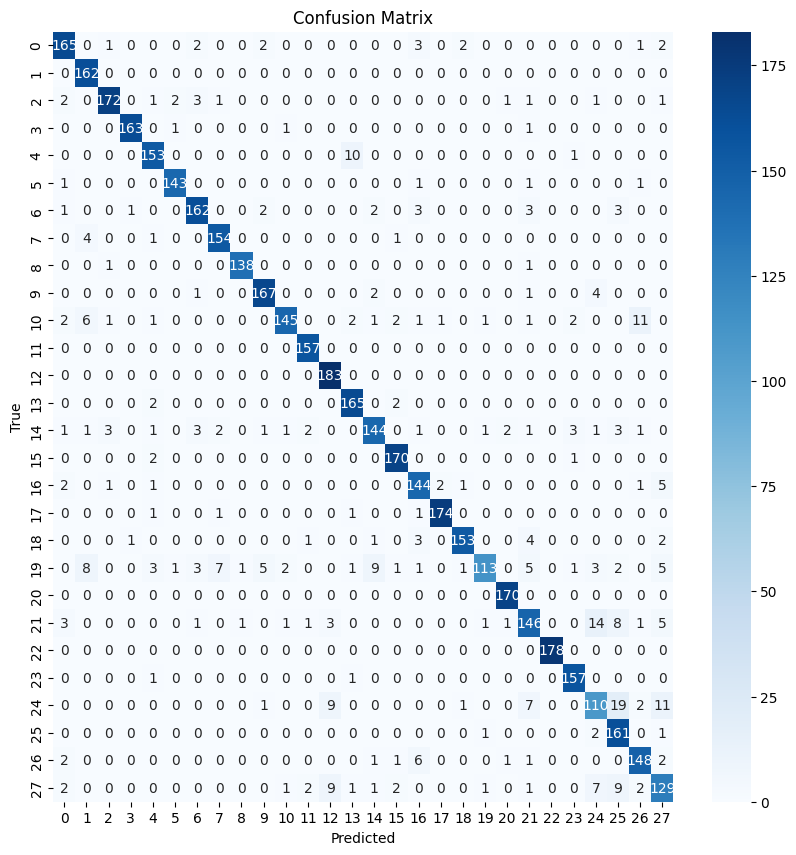

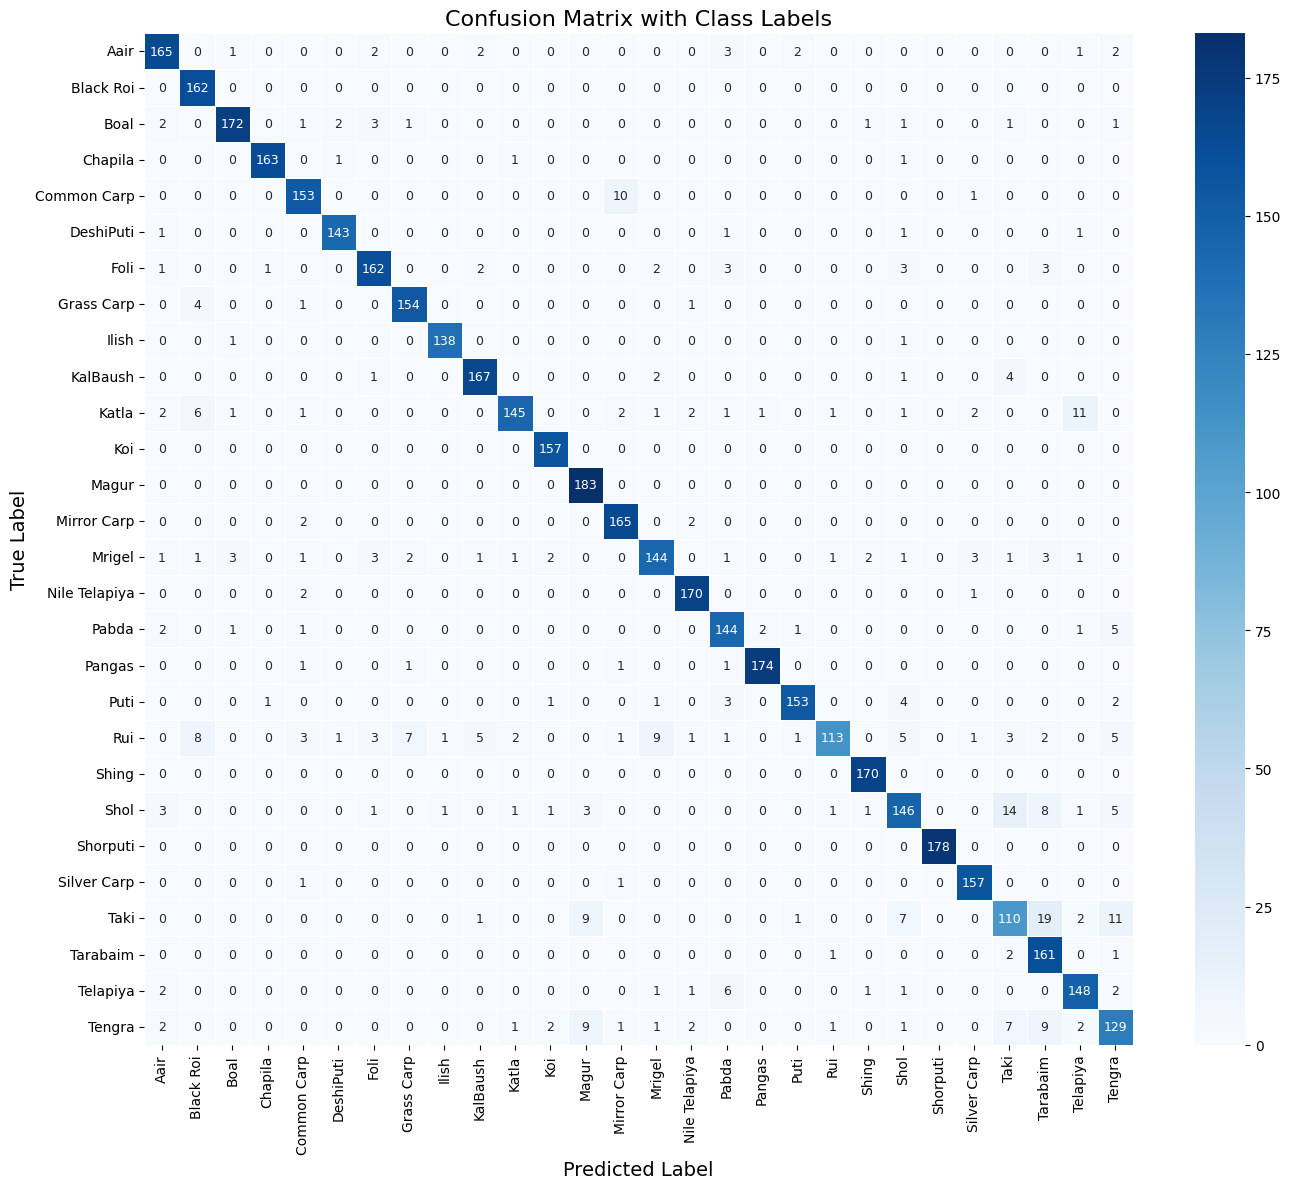

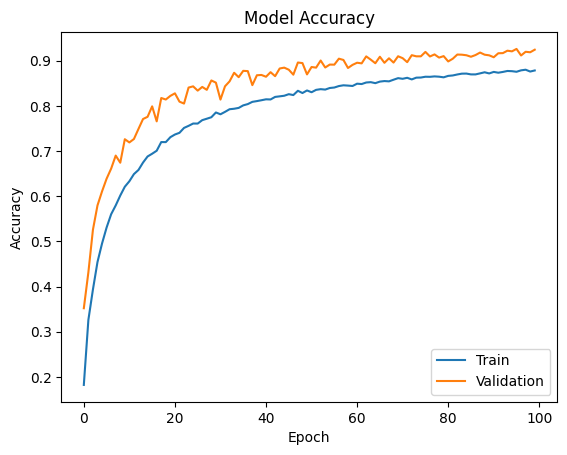

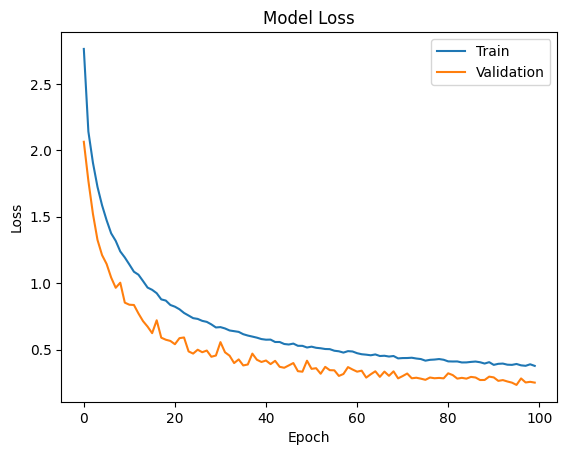

------------------------------------------------------------------------
Training for fold 8 ...
Epoch 1/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1282 - loss: 3.1645 - top-5-accuracy: 0.4250
Epoch 1: val_accuracy improved from -inf to 0.37474, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.1293 - loss: 3.1572 - top-5-accuracy: 0.4271 - val_accuracy: 0.3747 - val_loss: 1.9964 - val_top-5-accuracy: 0.7917
Epoch 2/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3229 - loss: 2.1844 - top-5-accuracy: 0.7440
Epoch 2: val_accuracy improved from 0.37474 to 0.42182, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3232 - loss: 2.1833 - top-5-accuracy: 0.7443 - val_accuracy: 0.4218 - val_loss: 1.8044 - val_top-5-accuracy: 0.8200
Epoch 3/100
278/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3726 - loss: 1.9770 - top-5-accuracy: 0.7990
Epoch 3: val_accuracy improved from 0.42182 

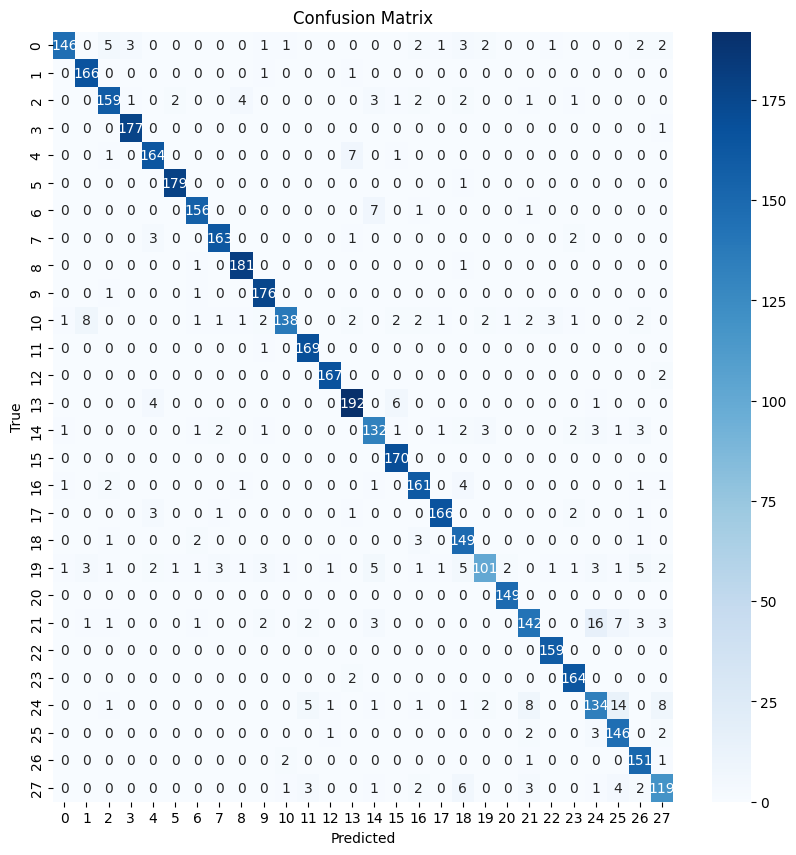

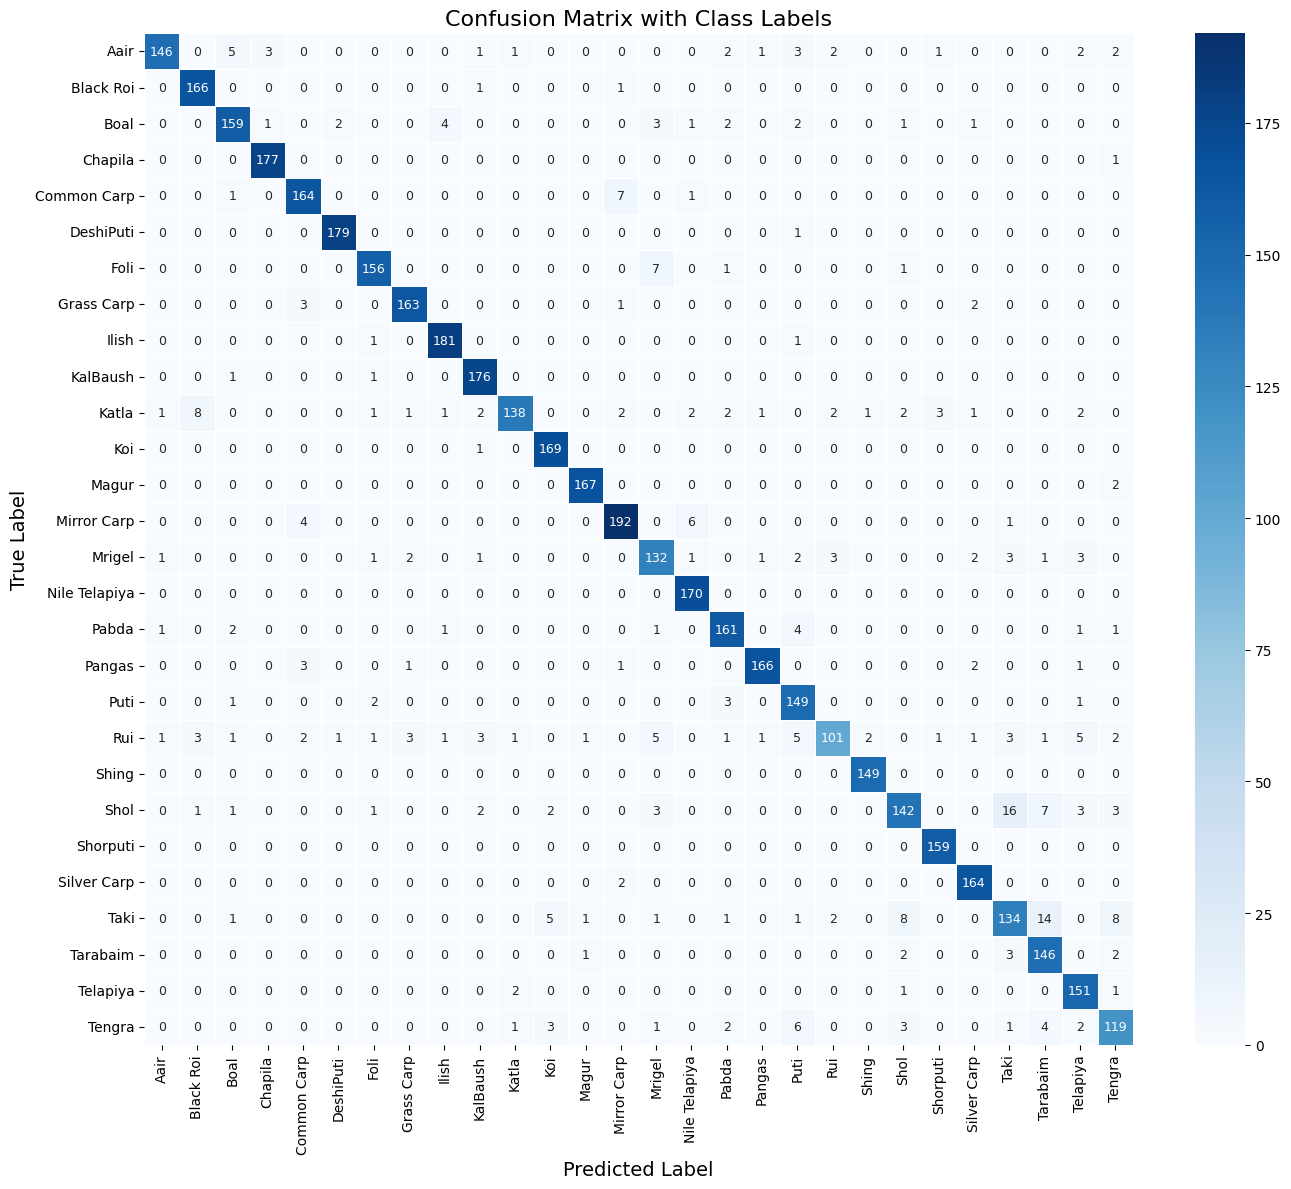

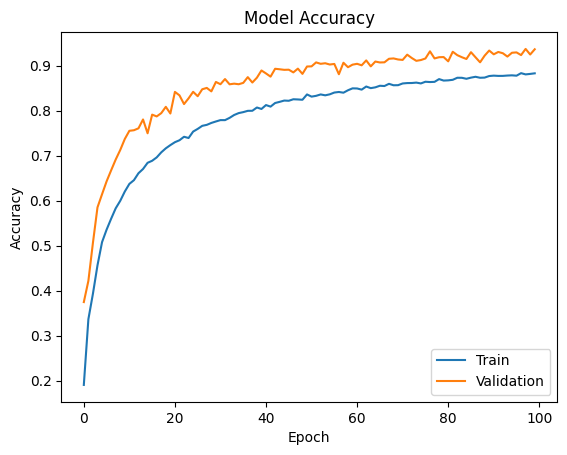

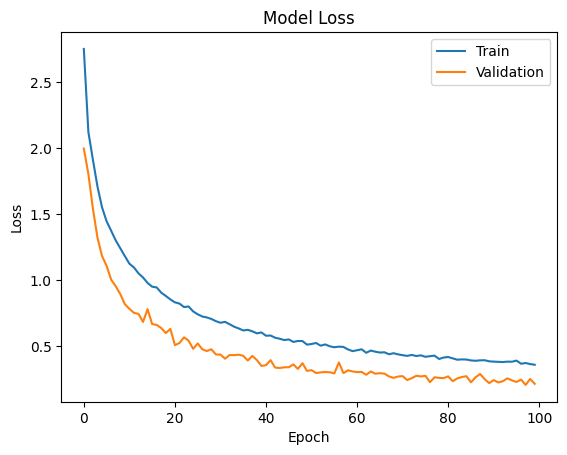

------------------------------------------------------------------------
Training for fold 9 ...
Epoch 1/100
280/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1307 - loss: 3.1526 - top-5-accuracy: 0.4296
Epoch 1: val_accuracy improved from -inf to 0.36530, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1314 - loss: 3.1483 - top-5-accuracy: 0.4309 - val_accuracy: 0.3653 - val_loss: 2.0157 - val_top-5-accuracy: 0.7810
Epoch 2/100
279/282 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3176 - loss: 2.1895 - top-5-accuracy: 0.7423
Epoch 2: val_accuracy improved from 0.36530 to 0.44056, saving model to model.weights.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.3179 - loss: 2.1886 - top-5-accuracy: 0.7425 - val_accuracy: 0.4406 - val_loss: 1.7750 - val_top-5-accuracy: 0.8243
Epoch 3/100
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3814 - loss: 1.9508 - top-5-accuracy: 0.7984
Epoch 3: val_accuracy improved from 0.44056 

In [ ]:
def run_experiment(model, x_train, y_train, x_test, y_test):
    optimizer = tf.optimizers.AdamW(
        learning_rate=learning_rate, weight_decay=weight_decay
    )
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            keras.metrics.SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
        ],
    )

    # ✅ Change to `.weights.h5` to match save_weights_only=True
    checkpoint_filepath = "model.weights.h5"
    checkpoint_callback = keras.callbacks.ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,  # Only saving weights
        mode="max",
        verbose=1
    )

    history = model.fit(
        x=x_train,
        y=y_train,
        batch_size=batch_size,
        epochs=num_epochs,
        validation_split=0.15,
        callbacks=[checkpoint_callback],
    )

    model.load_weights(checkpoint_filepath)
    _, accuracy, top_5_accuracy = model.evaluate(x_test, y_test)
    print(f"Test accuracy: {round(accuracy * 100, 2)}%")
    print(f"Test top 5 accuracy: {round(top_5_accuracy * 100, 2)}%")

    acc_per_fold.append(accuracy * 100)
    loss_per_fold.append(accuracy)  # You can replace with actual loss if needed

    # Prediction
    ypred = model.predict(x_test, verbose=1)
    ypred = np.argmax(ypred, axis=1)

    # Classification report
    target_names = [
        "Aair", "Black Roi", "Boal", "Chapila", "Common Carp", "DeshiPuti", "Foli",
        "Grass Carp", "Ilish", "KalBaush", "Katla", "Koi", 
        "Magur", "Mirror Carp", "Mrigel", "Nile Telapiya", "Pabda", "Pangas", "Puti",
        "Rui", "Shing", "Shol", "Shorputi", "Silver Carp", "Taki", "Tarabaim", "Telapiya", "Tengra"
    ]
    print(classification_report(y_test, ypred, target_names=target_names))

    # Confusion matrix
    cm = confusion_matrix(y_test, ypred)
    cm = pd.DataFrame(cm, range(28), range(28))
    plt.figure(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 10})
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()


    # Confusion matrix with class names
    cm = confusion_matrix(y_test, ypred)
    cm_df = pd.DataFrame(cm, index=target_names, columns=target_names)

    plt.figure(figsize=(14, 12))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", linewidths=.5, annot_kws={"size": 9})
    plt.title("Confusion Matrix with Class Labels", fontsize=16)
    plt.xlabel("Predicted Label", fontsize=14)
    plt.ylabel("True Label", fontsize=14)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Accuracy plot
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='lower right')
    plt.show()

    # Loss plot
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper right')
    plt.show()

    return history
kf = KFold(n_splits=10, shuffle=True)

for fold_no, (train_idx, test_idx) in enumerate(kf.split(x_train, y_train), start=1):
    print('------------------------------------------------------------------------')
    print(f'Training for fold {fold_no} ...')

    x_fold_train, y_fold_train = x_train[train_idx], y_train[train_idx]
    x_fold_test, y_fold_test = x_train[test_idx], y_train[test_idx]

    vit_classifier = create_vit_classifier()  # Create a new model for each fold
    history = run_experiment(vit_classifier, x_fold_train, y_fold_train, x_fold_test, y_fold_test)


In [34]:
vit_classifier = create_vit_classifier()
vit_classifier.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8             │ (None, 32, 32, 3)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ data_augmentation         │ (None, 32, 32, 3)      │              7 │ input_layer_8[0][0]    │
│ (Sequential)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ patches_8 (Patches)       │ (None, None, 108)      │              0 │ data_augmentation[7][… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ patch_encoder_7           │ (None, 25, 64)         │          8,576 │ patches_8[0][0]        │
│ (PatchEncoder)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization_21    │ (None, 25, 64)         │            128 │ patch_encoder_7[0][0]  │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ multi_head_attention_7    │ (None, 25, 64)         │         33,216 │ layer_normalization_2… │
│ (MultiHeadAttention)      │                        │                │ layer_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_14 (Add)              │ (None, 25, 64)         │              0 │ multi_head_attention_… │
│                           │                        │                │ patch_encoder_7[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization_22    │ (None, 25, 64)         │            128 │ add_14[0][0]           │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_43 (Dense)          │ (None, 25, 128)        │          8,320 │ layer_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_43 (Dropout)      │ (None, 25, 128)        │              0 │ dense_43[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_44 (Dense)          │ (None, 25, 64)         │          8,256 │ dropout_43[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_44 (Dropout)      │ (None, 25, 64)         │              0 │ dense_44[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_15 (Add)              │ (None, 25, 64)         │              0 │ dropout_44[0][0],      │
│                           │                        │                │ add_14[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ layer_normalization_23    │ (None, 25, 64)         │            128 │ add_15[0][0]           │
│ (LayerNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ flatten_7 (Flatten)       │ (None, 1600)           │              0 │ layer_normalization_2… │
├──────────────────────

 Total params: 5,464,483 (20.85 MB)

 Trainable params: 5,464,476 (20.85 MB)

 Non-trainable params: 7 (32.00 B)

In [38]:
# == Provide average scores ==
print('------------------------------------------------------------------------')
print('Score per fold')
for i in range(0, len(acc_per_fold)):
  print('------------------------------------------------------------------------')
  print(f'> Fold {i+1} - Loss: {loss_per_fold[i]} - Accuracy: {acc_per_fold[i]}%')
print('------------------------------------------------------------------------')
print('Average scores for all folds:')
print(f'> Accuracy: {np.mean(acc_per_fold)} (+- {np.std(acc_per_fold)})')
print(f'> Loss: {np.mean(loss_per_fold)}')
print('------------------------------------------------------------------------')

------------------------------------------------------------------------
Score per fold
------------------------------------------------------------------------
> Fold 1 - Loss: 0.9368622303009033 - Accuracy: 93.68622303009033%
------------------------------------------------------------------------
> Fold 2 - Loss: 0.9287840127944946 - Accuracy: 92.87840127944946%
------------------------------------------------------------------------
> Fold 3 - Loss: 0.922831654548645 - Accuracy: 92.2831654548645%
------------------------------------------------------------------------
> Fold 4 - Loss: 0.9268707633018494 - Accuracy: 92.68707633018494%
------------------------------------------------------------------------
> Fold 5 - Loss: 0.930272102355957 - Accuracy: 93.0272102355957%
------------------------------------------------------------------------
> Fold 6 - Loss: 0.9317601919174194 - Accuracy: 93.17601919174194%
------------------------------------------------------------------------
> F

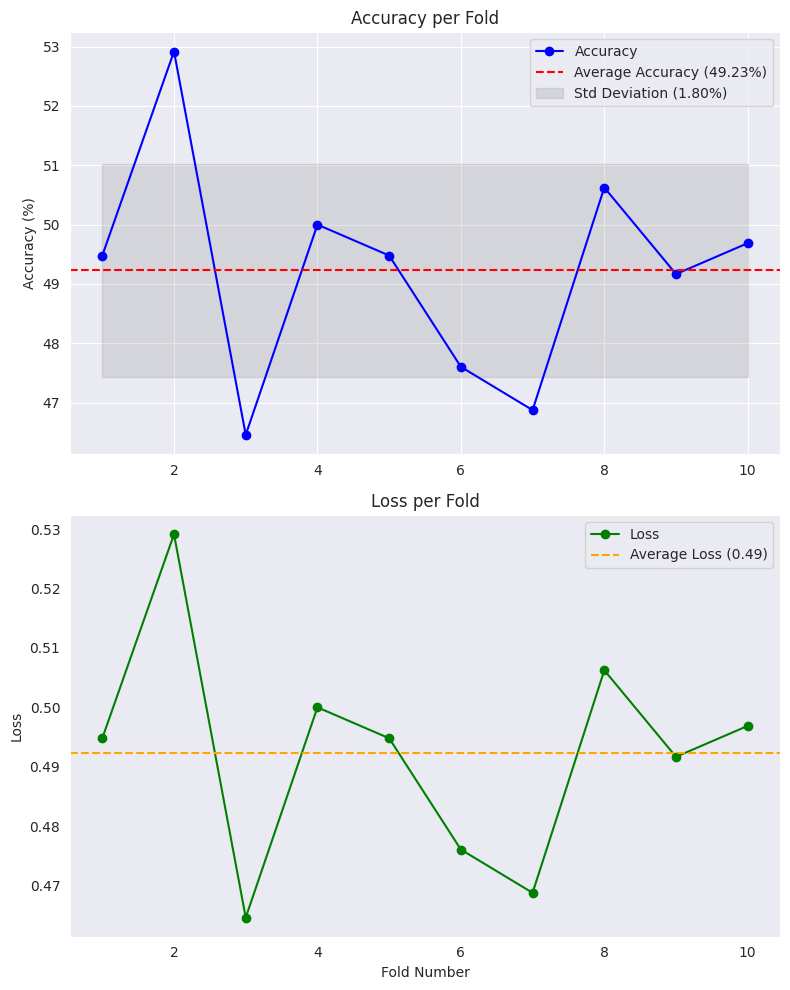

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Your existing code for printing scores

# Collect the average accuracy and loss scores
average_acc = np.mean(acc_per_fold)
std_acc = np.std(acc_per_fold)
average_loss = np.mean(loss_per_fold)

# Create a list of fold numbers
fold_numbers = range(1, len(acc_per_fold) + 1)

# Create subplots for accuracy and loss
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

# Plot accuracy
ax1.plot(fold_numbers, acc_per_fold, marker='o', linestyle='-', color='b', label='Accuracy')
ax1.axhline(average_acc, color='r', linestyle='--', label=f'Average Accuracy ({average_acc:.2f}%)')
ax1.fill_between(fold_numbers, average_acc - std_acc, average_acc + std_acc, color='gray', alpha=0.2, label=f'Std Deviation ({std_acc:.2f}%)')
ax1.set_ylabel('Accuracy (%)')
ax1.set_title('Accuracy per Fold')
ax1.legend()

# Plot loss
ax2.plot(fold_numbers, loss_per_fold, marker='o', linestyle='-', color='g', label='Loss')
ax2.axhline(average_loss, color='orange', linestyle='--', label=f'Average Loss ({average_loss:.2f})')
ax2.set_xlabel('Fold Number')
ax2.set_ylabel('Loss')
ax2.set_title('Loss per Fold')
ax2.legend()

# Show the plot
plt.tight_layout()
plt.grid()
plt.show()
